## Analytical solution to task list 1- 'Finite potential well FDM method'
using Newton Raphson
 $ z_{i+1} = z_i - \frac{f(x)}{f'(x0)}$, where f(x) changes as odd/even solution (in terms of symmetry)

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [77]:
h_bar = 1.054*10**(-34)  # in Js ?
m = 9.1*10**(-31)  # in kg
e = 1.6*10**(-19)  # in Coulombs
a = 0.1 * 10**(-9)   # in m
V0 = 100 *e   # in J
z0 = a* np.sqrt(2*m*V0/(h_bar**2))
print(z0)

z = np.linspace(0, 12, 1001)
f1 = np.tan(z)
f2 = np.sqrt((z0/z)**2 -1)
f3 = -(1/np.tan(z))  # cotangent function

5.11982450217535


/tmp/ipykernel_24732/156151038.py:11: RuntimeWarning: divide by zero encountered in divide
  f2 = np.sqrt((z0/z)**2 -1)
/tmp/ipykernel_24732/156151038.py:11: RuntimeWarning: invalid value encountered in sqrt
  f2 = np.sqrt((z0/z)**2 -1)
/tmp/ipykernel_24732/156151038.py:12: RuntimeWarning: divide by zero encountered in divide
  f3 = -(1/np.tan(z))  # cotangent function


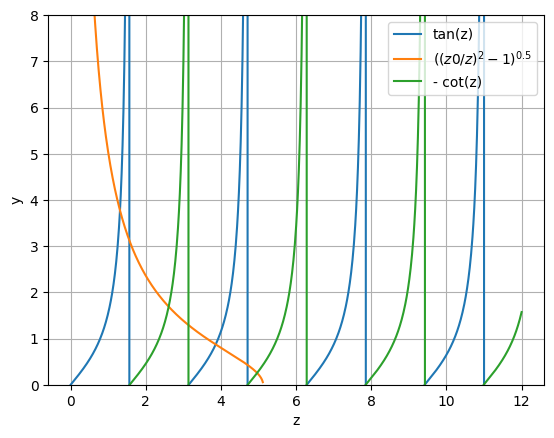

In [78]:
plt.plot(z, f1, label="tan(z)")
plt.plot(z, f2, label="$((z0/z)^{2} -1)^{0.5}$")
plt.plot(z, f3, label="- cot(z)") 
plt.legend()
plt.xlabel("z")
plt.ylabel("y")
plt.ylim(0,8)
plt.grid()
plt.show()

In [79]:
ratio = z0/(np.pi/2)
print("z0/(np.pi/2) =",ratio,"; No. of solutions/bound states :", np.ceil(ratio))
print()

z0/(np.pi/2) = 3.2593815091368366 ; No. of solutions/bound states : 4.0



$z = a(\frac{2m}{\bar{h}^2} \quad(V_0 - E))^{1/2}$

In [90]:
E0 = float(input("Enter a guess energy E0 (in eV):"))
E0 = E0*e
print("Input energy ", E0," J")

Input energy  1.12e-17  J


In [91]:
z = a* np.sqrt(2*m*(V0-E0)/(h_bar**2))
piby2 = np.pi/2
print("Pi/2=",piby2)
print("z=",z, ", z/(pi/2)=", z/piby2)
# V0 = V0/e

Pi/2= 1.5707963267948966
z= 2.8042433703090963 , z/(pi/2)= 1.785236776069476


In [92]:
for i in range(50):
    E1 = V0 - (1/(2*m))*(z*h_bar/a)**2 
    
    nn = 2*z/np.pi
    n = np.ceil(nn)
    print("2*z/np.pi= ",nn ,", No. of solutions contained",n)
    
    if (n%2 ==1 ):  # Odd solution fn
        f = lambda z: np.tan(z) - np.sqrt((z0/z)**2 -1)
        g = lambda z: (1/np.cos(z))**2 + z0**2/(z**3 *np.sqrt((z0/z)**2 -1))  # f'(x)
        # print("Odd soltn i=",i)
    elif (n%2 ==0):            # !EVEN solution 
        f = lambda z: -(1/np.tan(z)) - np.sqrt((z0/z)**2 -1)
        g = lambda z: (1/np.sin(z))**2 + z0**2/(z**3 *np.sqrt((z0/z)**2 -1))  # f'(x)
        # print("Even soltn i=",i)
        
    z2 = z - (f(z)/g(z))
    E2 = V0 - (1/(2*m))*(z2*h_bar/a)**2 
    
    if abs(E2-E1)/e < 1e-6:
        print("Converged!")
        print("Energy =", E2/e, "eV")
        print("i =",i, ", del E=",np.abs(E2-E1))
        print("z =", z2)
        break
    else:
        z = z2
        continue
        
    print("Loop ended! Energy =", E2/e, "eVi =",i, ", del E=",np.abs(E2-E1))
    
    # if (np.abs(E2-E1)/e > 10**(-6)):
    #     z = z2
    #     continue
    # else:
    #     print("Energy=", E2/e,", z=",z2)
    #     print("i =",i, ", del E=",np.abs(E2-E1))
    #     break

2*z/np.pi=  1.785236776069476 , No. of solutions contained 2.0
2*z/np.pi=  1.700185821933393 , No. of solutions contained 2.0
2*z/np.pi=  1.663496065238037 , No. of solutions contained 2.0
2*z/np.pi=  1.6598724978341033 , No. of solutions contained 2.0
2*z/np.pi=  1.6598446668338493 , No. of solutions contained 2.0
Converged!
Energy = 74.06629901720154 eV
i = 4 , del E= 8.024052771851073e-27
z = 2.6072779031917457
